# 08 — From Dynamic Programming to Reinforcement Learning

MPC, LMPC, dynamic programming, and reinforcement learning use different vocabulary but share a common object: **cost-to-go / value**. This notebook makes the connection explicit.

In [1]:
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

np.set_printoptions(precision=4, suppress=True)
plt.rcParams.update({"figure.figsize": (8, 4.5), "axes.grid": True})

## Table of Contents

- **[Part I — Bellman's principle of optimality](#part-1)**
- **[Part II — Infinite horizon and the Bellman fixed point](#part-2)**
- **[Part III — A tiny deterministic value-iteration example](#part-3)**
- **[Part IV — Where MPC and LMPC fit](#part-4)**
- **[Part V — The conceptual bridge to DQN](#part-5)**
- **[Part VI — Oral defense](#part-6)**


<a id="part-1"></a>
# Part I — Bellman's principle of optimality

For

$$
x_{k+1}=f(x_k,u_k)
$$

and finite-horizon cost

$$
J= g_N(x_N)+\sum_{k=0}^{N-1}g_k(x_k,u_k),
$$

the optimal value satisfies

$$
J_N^\star(x)=g_N(x),
$$

$$
J_k^\star(x)=\min_u\left[g_k(x,u)+J_{k+1}^\star(f(x,u))\right].
$$

Instead of optimizing the whole control sequence at once, dynamic programming recursively optimizes one action plus the optimal tail value.

<a id="part-2"></a>
# Part II — Infinite horizon and the Bellman fixed point

For stationary dynamics and cost,

$$
V^\star(x)=\min_u\left[\ell(x,u)+\gamma V^\star(f(x,u))\right].
$$

Define the state-action value

$$
Q^\star(x,u)=\ell(x,u)+\gamma V^\star(f(x,u)).
$$

Then

$$
V^\star(x)=\min_u Q^\star(x,u).
$$

Control usually minimizes cost; RL literature often maximizes reward. The two are equivalent after a sign change.

<a id="part-3"></a>
# Part III — A tiny deterministic value-iteration example

We use a one-dimensional grid with actions $u\in\{-1,0,1\}$, dynamics $x^+=\mathrm{clip}(x+u)$, and stage cost $x^2+0.2u^2$.

iterations: 10


Text(0, 0.5, 'optimal action')

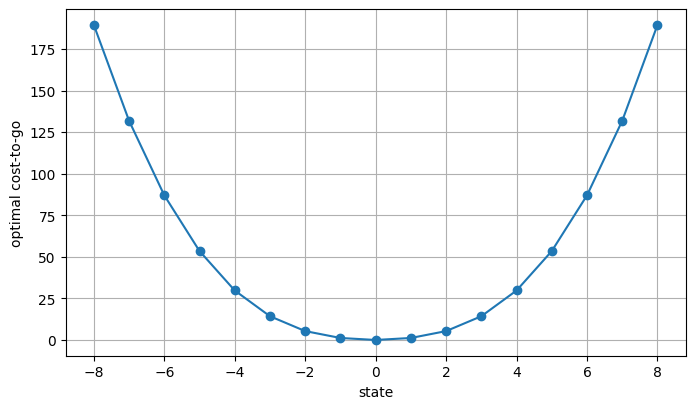

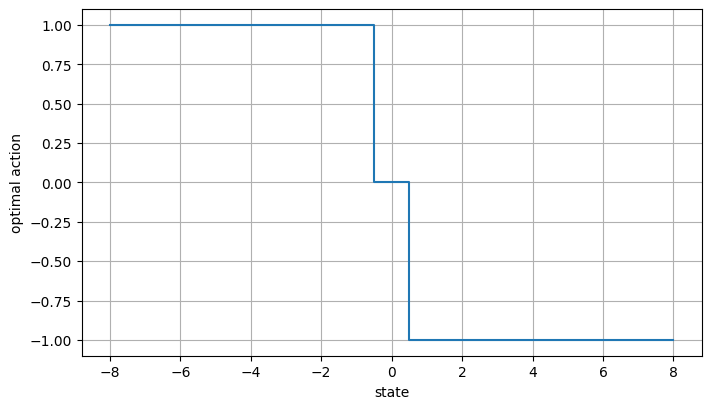

In [2]:
states=np.arange(-8,9)
actions=np.array([-1,0,1])
gamma=0.95
V=np.zeros(len(states))
policy=np.zeros(len(states),dtype=int)
for it in range(500):
    Vnew=np.zeros_like(V)
    for i,x in enumerate(states):
        qs=[]
        for u in actions:
            xn=int(np.clip(x+u,states[0],states[-1]))
            j=np.where(states==xn)[0][0]
            qs.append(x*x+0.2*u*u+gamma*V[j])
        Vnew[i]=min(qs); policy[i]=actions[int(np.argmin(qs))]
    if np.max(np.abs(Vnew-V))<1e-10: break
    V=Vnew
print('iterations:',it+1)
fig,ax=plt.subplots();ax.plot(states,V,'-o');ax.set_xlabel('state');ax.set_ylabel('optimal cost-to-go')
fig,ax=plt.subplots();ax.step(states,policy,where='mid');ax.set_xlabel('state');ax.set_ylabel('optimal action')

<a id="part-4"></a>
# Part IV — Where MPC and LMPC fit

- **Dynamic programming:** tries to represent the value function over the state space; exact methods face the curse of dimensionality.
- **MPC:** repeatedly solves a finite-horizon optimization online and uses a designed terminal approximation to the long-horizon tail.
- **LMPC:** learns a terminal safe set and a value approximation from repeated successful trajectories.
- **Model-free RL:** estimates values and/or policies from interaction without requiring the explicit model in the action-selection optimization.

A useful control/RL dictionary:

| Control | RL |
|---|---|
| system | environment |
| controller | agent |
| input | action |
| stage cost | negative reward |
| cost-to-go | negative value |
| system identification | model learning |
| policy evaluation | value prediction |

<a id="part-5"></a>
# Part V — The conceptual bridge to DQN

Q-learning uses the temporal-difference target

$$
y=r+\gamma\max_{a'}Q_{\theta^-}(s',a')
$$

for reward maximization. DQN replaces the Q-table by a neural approximator and stabilizes training using mechanisms such as experience replay and a target network.

LMPC and DQN both learn something related to long-term value, but they use it very differently:

- LMPC keeps a model-based constrained optimization online and uses sampled trajectories to construct terminal ingredients.
- DQN directly learns a state-action value that selects discrete actions.

<a id="part-6"></a>
# Part VI — Oral defense

- State Bellman's principle of optimality in words.
- Why does DP suffer from the curse of dimensionality?
- In what sense is an MPC terminal cost an approximation of the infinite-horizon tail?
- Why is LMPC not the same algorithm as Q-learning?